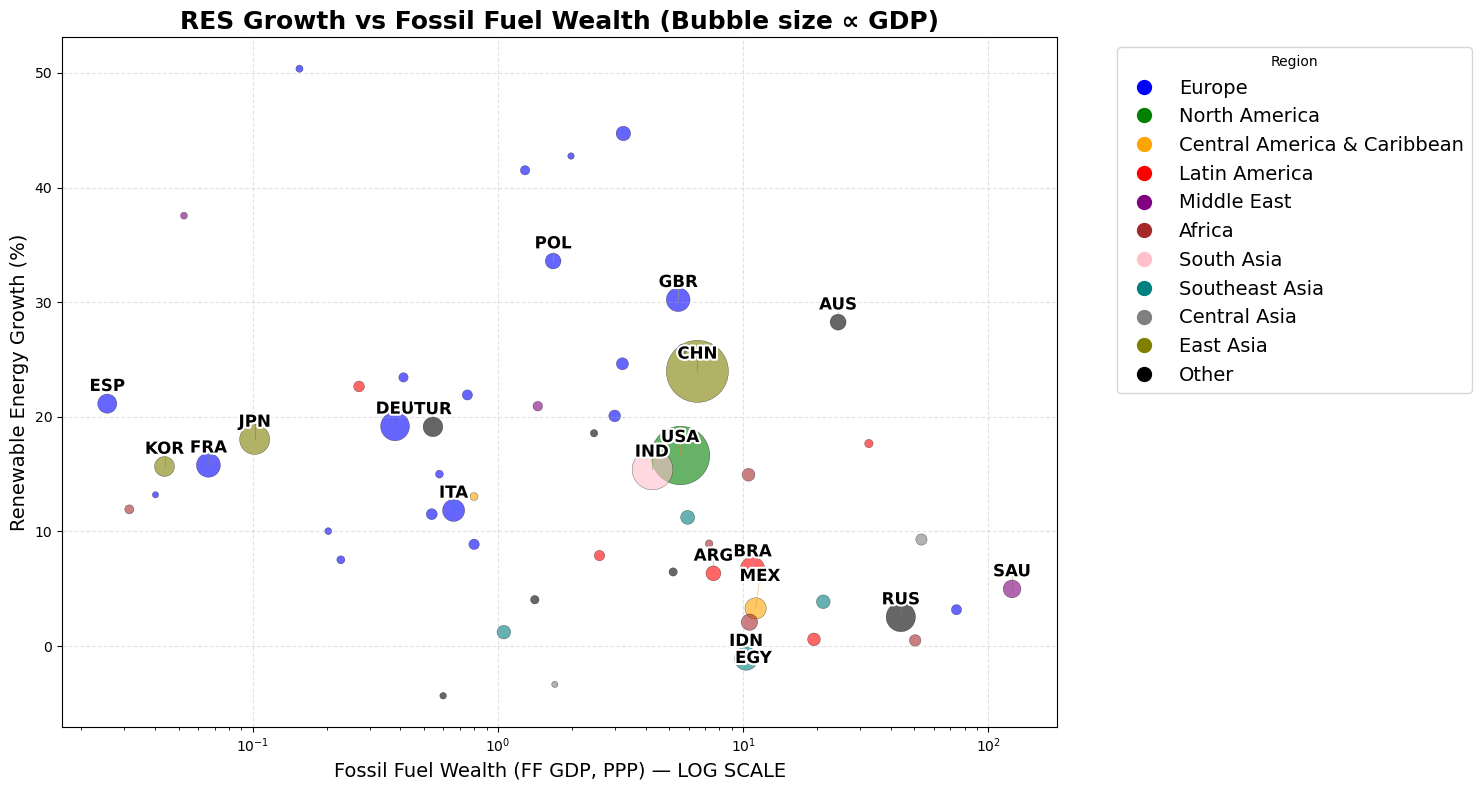

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patheffects import withStroke

# Load data
file_path = '../data/PRISMA_data_protocol.xlsx'
df = pd.read_excel(file_path, sheet_name=0, skiprows=10)

# --- Rename and clean columns ---
df.columns = [
    'Country', 'Code', 'Oil', 'Natural_gas', 'Coal',
    'Total_fossil', 'GDP_PPP', 'FF_GDP', 'RES_growth', 'GHG_change','GHG_intensity','Green_patents']

# --- Keep relevant rows (exclude missing key variables) ---
df = df.dropna(subset=['GDP_PPP', 'RES_growth', 'FF_GDP', 'GHG_change','GHG_intensity','Green_patents'])

# --- Convert numeric columns safely ---
numeric_cols = ['Oil', 'Natural_gas', 'Coal', 'Total_fossil', 
                'GDP_PPP', 'FF_GDP', 'RES_growth', 'GHG_change','GHG_intensity','Green_patents']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# --- Optional: Winsorize or cap extreme GHG values to avoid outlier distortion ---
df['GHG_change'] = df['GHG_change'].clip(lower=-50, upper=100)  # in %

# Remove invalid for log-scale
df = df[df['FF_GDP'] > 0]

# Region grouping
regions = {
    'Europe': ['ALB','AND','AUT','BEL','BGR','BIH','CZE','DNK','EST','FIN','FRA','DEU','GRC',
               'HUN','ISL','IRL','ITA','LVA','LTU','LUX','MLT','MDA','MCO','MNE','NLD','NOR',
               'POL','PRT','ROU','SRB','SVK','SVN','ESP','SWE','CHE','GBR','UKR'],
    'North America': ['CAN','USA'],
    'Central America & Caribbean': ['MEX','BLZ','GTM','HND','SLV','NIC','CRI','PAN','CUB',
                                    'DOM','HTI','JAM','BHS','BRB','TTO'],
    'Latin America': ['ARG','BOL','BRA','CHL','COL','ECU','GUY','PRY','PER','SUR','URY','VEN'],
    'Middle East': ['SAU','IRN','IRQ','ISR','JOR','KWT','LBN','OMN','QAT','SYR','ARE','YEM'],
    'Africa': ['DZA','AGO','EGY','ETH','GHA','KEN','LBR','LBY','MAR','MOZ','NGA','SDN','SEN',
               'TUN','ZAF','ZMB','ZWE'],
    'South Asia': ['AFG','BGD','BTN','IND','LKA','MDV','NPL','PAK'],
    'Southeast Asia': ['BRN','KHM','IDN','LAO','MYS','MMR','PHL','SGP','THA','TLS','VNM'],
    'Central Asia': ['KAZ','KGZ','TJK','TKM','UZB'],
    'East Asia': ['CHN','HKG','JPN','KOR','MNG','TWN']
}

def get_region(code):
    for region, codes in regions.items():
        if code in codes:
            return region
    return 'Other'

df['Region'] = df['Code'].apply(get_region)

# Color palette
region_colors = {
    'Europe': 'blue', 'North America': 'green',
    'Central America & Caribbean': 'orange', 'Latin America': 'red',
    'Middle East': 'purple', 'Africa': 'brown',
    'South Asia': 'pink', 'Southeast Asia': 'teal',
    'Central Asia': 'gray', 'East Asia': 'olive', 'Other': 'black'
}

# Compute normalized bubble sizes
min_size = 20
max_size = 2000
gdp_min, gdp_max = df['GDP_PPP'].min(), df['GDP_PPP'].max()

df['bubble_size'] = min_size + (df['GDP_PPP'] - gdp_min) / (gdp_max - gdp_min) * (max_size - min_size)

# Top 20 GDP economies labeled
top20 = df.nlargest(20, 'GDP_PPP')

# Plot
plt.figure(figsize=(15, 8))

for region, color in region_colors.items():
    subset = df[df['Region'] == region]
    if not subset.empty:
        plt.scatter(
            subset['FF_GDP'], subset['RES_growth'],
            s=subset['bubble_size'],
            c=color, alpha=0.60, label=region,
            edgecolors='k', linewidth=0.3
        )

# Smart label placement for top 20
for _, row in top20.iterrows():
    x, y = row['FF_GDP'], row['RES_growth']

    nearby = top20[
        (abs(top20['FF_GDP'] - x) < x * 0.15) &
        (abs(top20['RES_growth'] - y) < 5)
    ]

    dx, dy = 0.0, 1.5
    if len(nearby) > 3:
        angle = np.random.uniform(0, 2*np.pi)
        dx = np.cos(angle) * x * 0.05
        dy = np.sin(angle) * 5

    plt.plot([x, x+dx], [y, y+dy], linewidth=0.8, alpha=0.35)

    plt.text(
        x + dx, y + dy, row['Code'],
        fontsize=12, fontweight='bold',
        ha='center', va='center',
        path_effects=[withStroke(linewidth=3, foreground="white")]
    )

# Final formatting
plt.xscale('log')
plt.grid(alpha=0.35, linestyle='--')
plt.xlabel('Fossil Fuel Wealth (FF GDP, PPP) — LOG SCALE', fontsize=14)
plt.ylabel('Renewable Energy Growth (%)', fontsize=14)
plt.title('RES Growth vs Fossil Fuel Wealth (Bubble size ∝ GDP)', fontsize=18, fontweight='bold')
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')

# Create proxy artists for legend (fixed-size markers)
handles = []
for region, color in region_colors.items():
    handles.append(plt.Line2D([], [], marker='o', color=color,
                              linestyle='None', markersize=10))

plt.legend(handles, region_colors.keys(),
           title='Region', bbox_to_anchor=(1.05, 1),
           loc='upper left', fontsize=14)

plt.tight_layout()
plt.show()


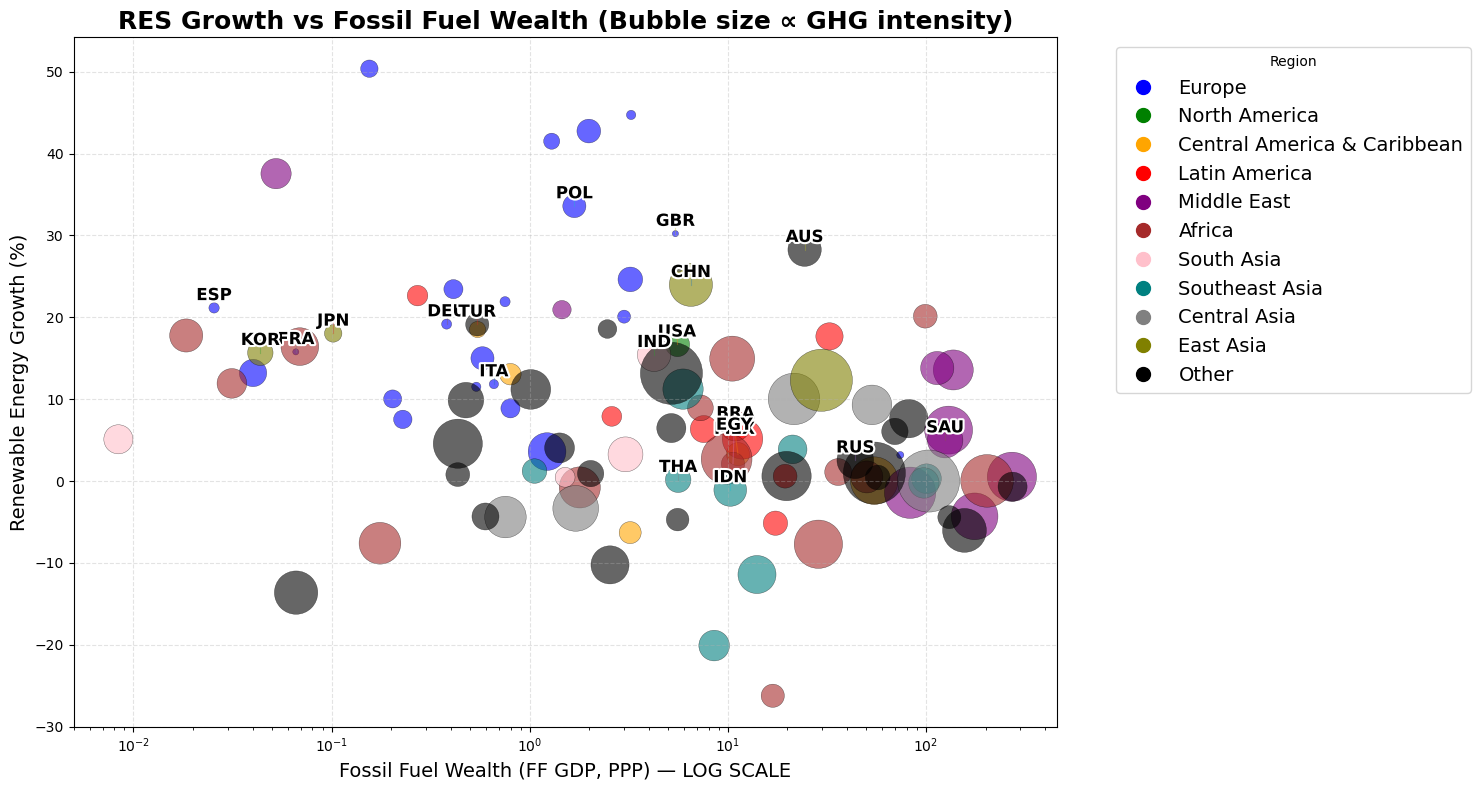

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patheffects import withStroke

# Load data
file_path = '../data/PRISMA_data_protocol.xlsx'
df = pd.read_excel(file_path, sheet_name=0, skiprows=10)

# --- Rename and clean columns ---
df.columns = [
    'Country', 'Code', 'Oil', 'Natural_gas', 'Coal',
    'Total_fossil', 'GDP_PPP', 'FF_GDP', 'RES_growth', 'GHG_change',
    'GHG_intensity', 'Green_patents'
]

# --- Convert numeric columns safely ---
numeric_cols = [
    'Oil', 'Natural_gas', 'Coal', 'Total_fossil',
    'GDP_PPP', 'FF_GDP', 'RES_growth', 'GHG_change',
    'GHG_intensity', 'Green_patents'
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# --- Keep relevant rows (exclude missing key variables) ---
# NOTE: now we must keep GHG_intensity since it drives bubble size
df = df.dropna(subset=['FF_GDP', 'RES_growth', 'GHG_intensity', 'GDP_PPP'])

# --- Optional: cap extreme values to avoid outlier distortion ---
df['GHG_change'] = df['GHG_change'].clip(lower=-50, upper=100)  # in %

# Remove invalid for log-scale
df = df[df['FF_GDP'] > 0]

# Region grouping
regions = {
    'Europe': ['ALB','AND','AUT','BEL','BGR','BIH','CZE','DNK','EST','FIN','FRA','DEU','GRC',
               'HUN','ISL','IRL','ITA','LVA','LTU','LUX','MLT','MDA','MCO','MNE','NLD','NOR',
               'POL','PRT','ROU','SRB','SVK','SVN','ESP','SWE','CHE','GBR','UKR'],
    'North America': ['CAN','USA'],
    'Central America & Caribbean': ['MEX','BLZ','GTM','HND','SLV','NIC','CRI','PAN','CUB',
                                    'DOM','HTI','JAM','BHS','BRB','TTO'],
    'Latin America': ['ARG','BOL','BRA','CHL','COL','ECU','GUY','PRY','PER','SUR','URY','VEN'],
    'Middle East': ['SAU','IRN','IRQ','ISR','JOR','KWT','LBN','OMN','QAT','SYR','ARE','YEM'],
    'Africa': ['DZA','AGO','EGY','ETH','GHA','KEN','LBR','LBY','MAR','MOZ','NGA','SDN','SEN',
               'TUN','ZAF','ZMB','ZWE'],
    'South Asia': ['AFG','BGD','BTN','IND','LKA','MDV','NPL','PAK'],
    'Southeast Asia': ['BRN','KHM','IDN','LAO','MYS','MMR','PHL','SGP','THA','TLS','VNM'],
    'Central Asia': ['KAZ','KGZ','TJK','TKM','UZB'],
    'East Asia': ['CHN','HKG','JPN','KOR','MNG','TWN']
}

def get_region(code):
    for region, codes in regions.items():
        if code in codes:
            return region
    return 'Other'

df['Region'] = df['Code'].astype(str).str.strip().str.upper().apply(get_region)

# Color palette
region_colors = {
    'Europe': 'blue', 'North America': 'green',
    'Central America & Caribbean': 'orange', 'Latin America': 'red',
    'Middle East': 'purple', 'Africa': 'brown',
    'South Asia': 'pink', 'Southeast Asia': 'teal',
    'Central Asia': 'gray', 'East Asia': 'olive', 'Other': 'black'
}

# ==========================================================
# Bubble size now proportional to GHG_intensity (NOT GDP_PPP)
# ==========================================================
min_size = 20
max_size = 2000

# optional: clip extremes to prevent a few huge bubbles dominating
ghg_clip_lo, ghg_clip_hi = df['GHG_intensity'].quantile([0.02, 0.98])
df['GHG_intensity_clip'] = df['GHG_intensity'].clip(ghg_clip_lo, ghg_clip_hi)

ghg_min, ghg_max = df['GHG_intensity_clip'].min(), df['GHG_intensity_clip'].max()
if ghg_max > ghg_min:
    df['bubble_size'] = min_size + (df['GHG_intensity_clip'] - ghg_min) / (ghg_max - ghg_min) * (max_size - min_size)
else:
    df['bubble_size'] = (min_size + max_size) / 2

# Top 20 GDP economies labeled (same as before)
top20 = df.nlargest(20, 'GDP_PPP')

# Plot
plt.figure(figsize=(15, 8))

for region, color in region_colors.items():
    subset = df[df['Region'] == region]
    if not subset.empty:
        plt.scatter(
            subset['FF_GDP'], subset['RES_growth'],
            s=subset['bubble_size'],
            c=color, alpha=0.60, label=region,
            edgecolors='k', linewidth=0.3
        )

# Smart label placement for top 20
for _, row in top20.iterrows():
    x, y = row['FF_GDP'], row['RES_growth']

    nearby = top20[
        (abs(top20['FF_GDP'] - x) < x * 0.15) &
        (abs(top20['RES_growth'] - y) < 5)
    ]

    dx, dy = 0.0, 1.5
    if len(nearby) > 3:
        angle = np.random.uniform(0, 2*np.pi)
        dx = np.cos(angle) * x * 0.05
        dy = np.sin(angle) * 5

    plt.plot([x, x+dx], [y, y+dy], linewidth=0.8, alpha=0.35)

    plt.text(
        x + dx, y + dy, row['Code'],
        fontsize=12, fontweight='bold',
        ha='center', va='center',
        path_effects=[withStroke(linewidth=3, foreground="white")]
    )

# Final formatting
plt.xscale('log')
plt.grid(alpha=0.35, linestyle='--')
plt.xlabel('Fossil Fuel Wealth (FF GDP, PPP) — LOG SCALE', fontsize=14)
plt.ylabel('Renewable Energy Growth (%)', fontsize=14)
plt.title('RES Growth vs Fossil Fuel Wealth (Bubble size ∝ GHG intensity)', fontsize=18, fontweight='bold')

# Proxy artists for legend (fixed-size markers)
handles = []
for region, color in region_colors.items():
    handles.append(plt.Line2D([], [], marker='o', color=color,
                              linestyle='None', markersize=10))

plt.legend(handles, region_colors.keys(),
           title='Region', bbox_to_anchor=(1.05, 1),
           loc='upper left', fontsize=14)

plt.tight_layout()
plt.show()


In [3]:
import numpy as np
import pandas as pd

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

import plotly.express as px


# =========================
# 0) Settings you can tweak
# =========================
PATH = "../data/PRISMA_data_protocol.xlsx"
N_COMPONENTS = 3
RANDOM_STATE = 42

# Option 1 knobs (often helps balance):
WINSOR_LO, WINSOR_HI = 0.02, 0.98     # try 0.01/0.99 if you want milder clipping
COV_TYPE = "diag"                    # key for preventing one cluster swallowing most countries
N_INIT = 50                          # more stable fits


# =========================
# 1) Load + basic cleaning
# =========================
df_all = pd.read_excel(PATH, sheet_name=0, skiprows=8)

df_all = df_all.replace({"..": np.nan, "#VALUE!": np.nan, "#N/A": np.nan, "": np.nan})

# Standardize key column names (adjust here if your headers differ)
df_all = df_all.rename(
    columns={
        "Country code": "Code",
        "FF/GDP": "FF_GDP",
        "RES grwth": "RES_growth",
    }
)

# Clean ISO3 codes
df_all["Code"] = df_all["Code"].astype(str).str.strip().str.upper()
df_all = df_all.dropna(subset=["Code"])
df_all = df_all[df_all["Code"].str.len() == 3].copy()
df_all = df_all.drop_duplicates(subset=["Code"], keep="first").copy()

# Make sure numeric
for c in ["FF_GDP", "RES_growth", "GHG_intensity"]:
    if c not in df_all.columns:
        raise ValueError(f"Missing required column: {c}")
    df_all[c] = pd.to_numeric(df_all[c], errors="coerce")

# ------------------------------------------
# 1b) Treat placeholder 0 in FF_GDP as NaN
#     (only when it looks like a missing-code)
# ------------------------------------------
# Try to detect "fossil components" columns if they exist
possible_fossil_cols = [
    "Oil", "Natural gas", "Coal", "Total fossil fuels",
    "Oil ", "Natural gas ", "Coal ", "Total fossil fuels "
]
fossil_cols = [c for c in possible_fossil_cols if c in df_all.columns]

if fossil_cols:
    for c in fossil_cols:
        df_all[c] = pd.to_numeric(df_all[c], errors="coerce")

    # Placeholder zero: FF_GDP==0 AND all fossil component columns sum to 0 (or are missing)
    fossil_sum = df_all[fossil_cols].fillna(0).sum(axis=1)
    placeholder_zero = (df_all["FF_GDP"] == 0) & (fossil_sum == 0)
    df_all.loc[placeholder_zero, "FF_GDP"] = np.nan
else:
    # Fallback: at least fix Canada (your reported case)
    df_all.loc[(df_all["Code"] == "CAN") & (df_all["FF_GDP"] == 0), "FF_GDP"] = np.nan


# ==========================================
# 2) Option 1: transform + winsorize + scale
#    Fit clustering only where features exist
#    BUT keep all countries in df_all
# ==========================================
raw_features = ["FF_GDP", "RES_growth", "GHG_intensity"]
fit_mask = df_all[raw_features].notna().all(axis=1)

df_fit = df_all.loc[fit_mask, ["Code", "Country"] + raw_features].copy()

# Transform skewed variables
df_fit["FF_GDP_t"] = np.log1p(df_fit["FF_GDP"])
df_fit["GHG_intensity_t"] = np.log1p(df_fit["GHG_intensity"])

# RES_growth can be negative, so leave as-is
df_fit["RES_growth_t"] = df_fit["RES_growth"]

features_t = ["FF_GDP_t", "RES_growth_t", "GHG_intensity_t"]

# Winsorize (clip extremes)
for c in features_t:
    lo, hi = df_fit[c].quantile([WINSOR_LO, WINSOR_HI])
    df_fit[c] = df_fit[c].clip(lo, hi)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fit[features_t].to_numpy())

# Fit GMM (diag covariance usually yields more balanced components)
gmm = GaussianMixture(
    n_components=N_COMPONENTS,
    covariance_type=COV_TYPE,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
    init_params="kmeans",
    reg_covar=1e-6,
)
df_fit["_cluster"] = gmm.fit_predict(X_scaled)

# Inspect raw component sizes (this is what you care about for balance)
raw_sizes = pd.Series(df_fit["_cluster"]).value_counts().sort_index()
print("Raw component sizes:", raw_sizes.to_dict())


# =========================
# 3) Name the components
#    (naming doesn't change sizes)
# =========================
centroids_t = pd.DataFrame(
    scaler.inverse_transform(gmm.means_),
    columns=features_t
)
centroids_t["cluster"] = np.arange(len(centroids_t))

# Back-transform to original scales for interpretation
centroids_t["FF_GDP_center"] = np.expm1(centroids_t["FF_GDP_t"])
centroids_t["GHG_intensity_center"] = np.expm1(centroids_t["GHG_intensity_t"])
centroids_t["RES_growth_center"] = centroids_t["RES_growth_t"]

# Fossil-dependent = highest FF_GDP centroid
fossil_cluster = int(centroids_t.sort_values("FF_GDP_center", ascending=False).iloc[0]["cluster"])

# Transition leaders = among remaining, higher RES growth + lower GHG intensity + lower FF_GDP
remaining = centroids_t[centroids_t["cluster"] != fossil_cluster].copy()
remaining["transition_score"] = (
    remaining["RES_growth_center"].rank(ascending=False)
    + remaining["GHG_intensity_center"].rank(ascending=True)
    + remaining["FF_GDP_center"].rank(ascending=True)
)
transition_cluster = int(remaining.sort_values("transition_score").iloc[0]["cluster"])

diversifying_cluster = int(
    [c for c in centroids_t["cluster"].tolist() if c not in [fossil_cluster, transition_cluster]][0]
)

label_map = {
    fossil_cluster: "Fossil-dependent economies",
    diversifying_cluster: "Diversifying economies",
    transition_cluster: "Transition leaders",
}
df_fit["Cluster"] = df_fit["_cluster"].map(label_map)

print("Cluster centroids (original scale):")
print(
    centroids_t[["cluster", "FF_GDP_center", "RES_growth_center", "GHG_intensity_center"]]
    .sort_values("cluster")
    .to_string(index=False)
)
print("Labeled sizes:", df_fit["Cluster"].value_counts().to_dict())


# ==========================================
# 4) Merge back so ALL countries stay visible
# ==========================================
df_all = df_all.merge(df_fit[["Code", "Cluster"]], on="Code", how="left")
df_all["Cluster"] = df_all["Cluster"].fillna("No data")


# ==========================================
# 4b) Diagnose which variables are missing
#     for "No data" countries
# ==========================================
feature_display = {
    "FF_GDP":        "Fossil wealth",
    "RES_growth":    "Renewables growth",
    "GHG_intensity": "GHG intensity",
}

def missing_label(row):
    missing = [label for col, label in feature_display.items()
               if pd.isna(row.get(col))]
    return ", ".join(missing) if missing else "complete"

df_all["Missing_vars"] = df_all.apply(missing_label, axis=1)

no_data_df = (
    df_all[df_all["Cluster"] == "No data"]
    [["Code", "Country", "FF_GDP", "RES_growth", "GHG_intensity", "Missing_vars"]]
    .sort_values("Missing_vars")
    .reset_index(drop=True)
)

n_no_data = len(no_data_df)
print(f"\n{'='*60}")
print(f"Countries with insufficient data for clustering: {n_no_data}")
print(f"{'='*60}")
print("\nBreakdown by missing variable(s):")
breakdown = no_data_df.groupby("Missing_vars")["Code"].agg(list)
for miss_type, codes in breakdown.items():
    print(f"  {miss_type} ({len(codes)}):  {', '.join(codes)}")

print("\nFull list:")
display(no_data_df.to_string(index=False))


# =========================
# 5) Plot map (ALL countries)
# =========================
color_map = {
    "Fossil-dependent economies": "#66c2a5",
    "Diversifying economies": "#fc8d62",
    "Transition leaders": "#8da0cb",
    "No data": "#6f6f6f",
}

# Build a readable hover column for missing variables
df_all["Info"] = df_all.apply(
    lambda r: f"Missing: {r['Missing_vars']}" if r["Cluster"] == "No data" else r["Cluster"],
    axis=1
)

fig = px.choropleth(
    df_all,
    locations="Code",
    locationmode="ISO-3",
    color="Cluster",
    hover_name="Country",
    hover_data={
        "Code": True,
        "Info": True,         # shows cluster name OR "Missing: ..." for no-data countries
        "FF_GDP": ":.2f",
        "RES_growth": ":.1f",
        "GHG_intensity": ":.3f",
        "Cluster": False,     # suppress duplicate (already shown via Info)
        "Missing_vars": False,
    },
    projection="natural earth",
    title="Country Clusters Based on Fossil Dependence, Renewable Growth, and GHG Intensity",
    color_discrete_map=color_map,
)

fig.update_geos(
    showcoastlines=True,
    coastlinecolor="black",
    showcountries=True,
    countrycolor="black",
    showland=True,
    landcolor="white",
)

# ── Annotation: no-data summary ───────────────────────────────
breakdown_lines = [f"  {miss}: {', '.join(codes)}"
                   for miss, codes in breakdown.items()]
annotation_text = (
    f"<b>No data: {n_no_data} countries</b><br>"
    + "<br>".join(
        f"Missing {miss} ({len(codes)}): {', '.join(codes)}"
        for miss, codes in breakdown.items()
    )
)

fig.add_annotation(
    text=annotation_text,
    xref="paper", yref="paper",
    x=0.01, y=-0.05,
    showarrow=False,
    font=dict(size=10, color="#444"),
    align="left",
    bgcolor="rgba(255,255,255,0.85)",
    bordercolor="#aaa",
    borderwidth=1,
    borderpad=5,
)

fig.update_layout(margin=dict(b=120))   # extra bottom margin so annotation fits

fig.show()


C:\Users\Dibella\AppData\Local\Temp\ipykernel_25668\616023971.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_all = df_all.replace({"..": np.nan, "#VALUE!": np.nan, "#N/A": np.nan, "": np.nan})
C:\Users\Dibella\miniconda3\envs\pypsa-eur\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Dibella\miniconda3\envs\pypsa-eur\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_inf

Raw component sizes: {0: 35, 1: 43, 2: 31}
Cluster centroids (original scale):
 cluster  FF_GDP_center  RES_growth_center  GHG_intensity_center
       0       0.949642          19.727760              0.205055
       1       3.815788           4.252754              0.404794
       2      59.849767           3.386808              0.565006
Labeled sizes: {'Diversifying economies': 43, 'Transition leaders': 35, 'Fossil-dependent economies': 31}

Countries with insufficient data for clustering: 107

Breakdown by missing variable(s):
  Fossil wealth (70):  LBR, LSO, LBN, LVA, LAO, KNA, LCA, LKA, KIR, ISL, HKG, HND, HTI, GUY, GNB, JAM, LUX, SOM, SLB, PLW, PRT, NIC, RWA, WSM, NAM, STP, SYC, SLE, MUS, MRT, SGP, MLT, MLI, MDV, PAN, SWE, GIN, GRL, UGA, CAF, URY, CAN, CPV, BDI, COM, BFA, BTN, BEL, BHS, ABW, ARM, ATG, VUT, GRD, CRI, PRY, TON, CYP, DJI, DMA, DOM, SLV, TGO, ETH, FRO, CHE, FJI, FIN, SYR, GMB
  Fossil wealth, GHG intensity (20):  VIR, TUV, SSD, VEN, MAF, ASM, NCL, AND, VGB, CUB, CUW, E

"Code                        Country   FF_GDP  RES_growth  GHG_intensity                                    Missing_vars\n LBR                        Liberia      NaN       44.32       0.547310                                   Fossil wealth\n LSO                        Lesotho      NaN       -0.49       0.491512                                   Fossil wealth\n LBN                        Lebanon      NaN       24.85       0.192717                                   Fossil wealth\n LVA                         Latvia      NaN        8.36       0.173948                                   Fossil wealth\n LAO                        Lao PDR      NaN      -13.75       0.749707                                   Fossil wealth\n KNA            St. Kitts and Nevis      NaN        2.55       0.129053                                   Fossil wealth\n LCA                      St. Lucia      NaN        5.40       0.115167                                   Fossil wealth\n LKA                      Sri L

Countries in shapefile with no WP6 protocol assignment: 6

  FLK  Falkland Is.
  ATF  Fr. S. Antarctic Lands
  MKD  Macedonia
  PRI  Puerto Rico
  TWN  Taiwan
  ESH  W. Sahara


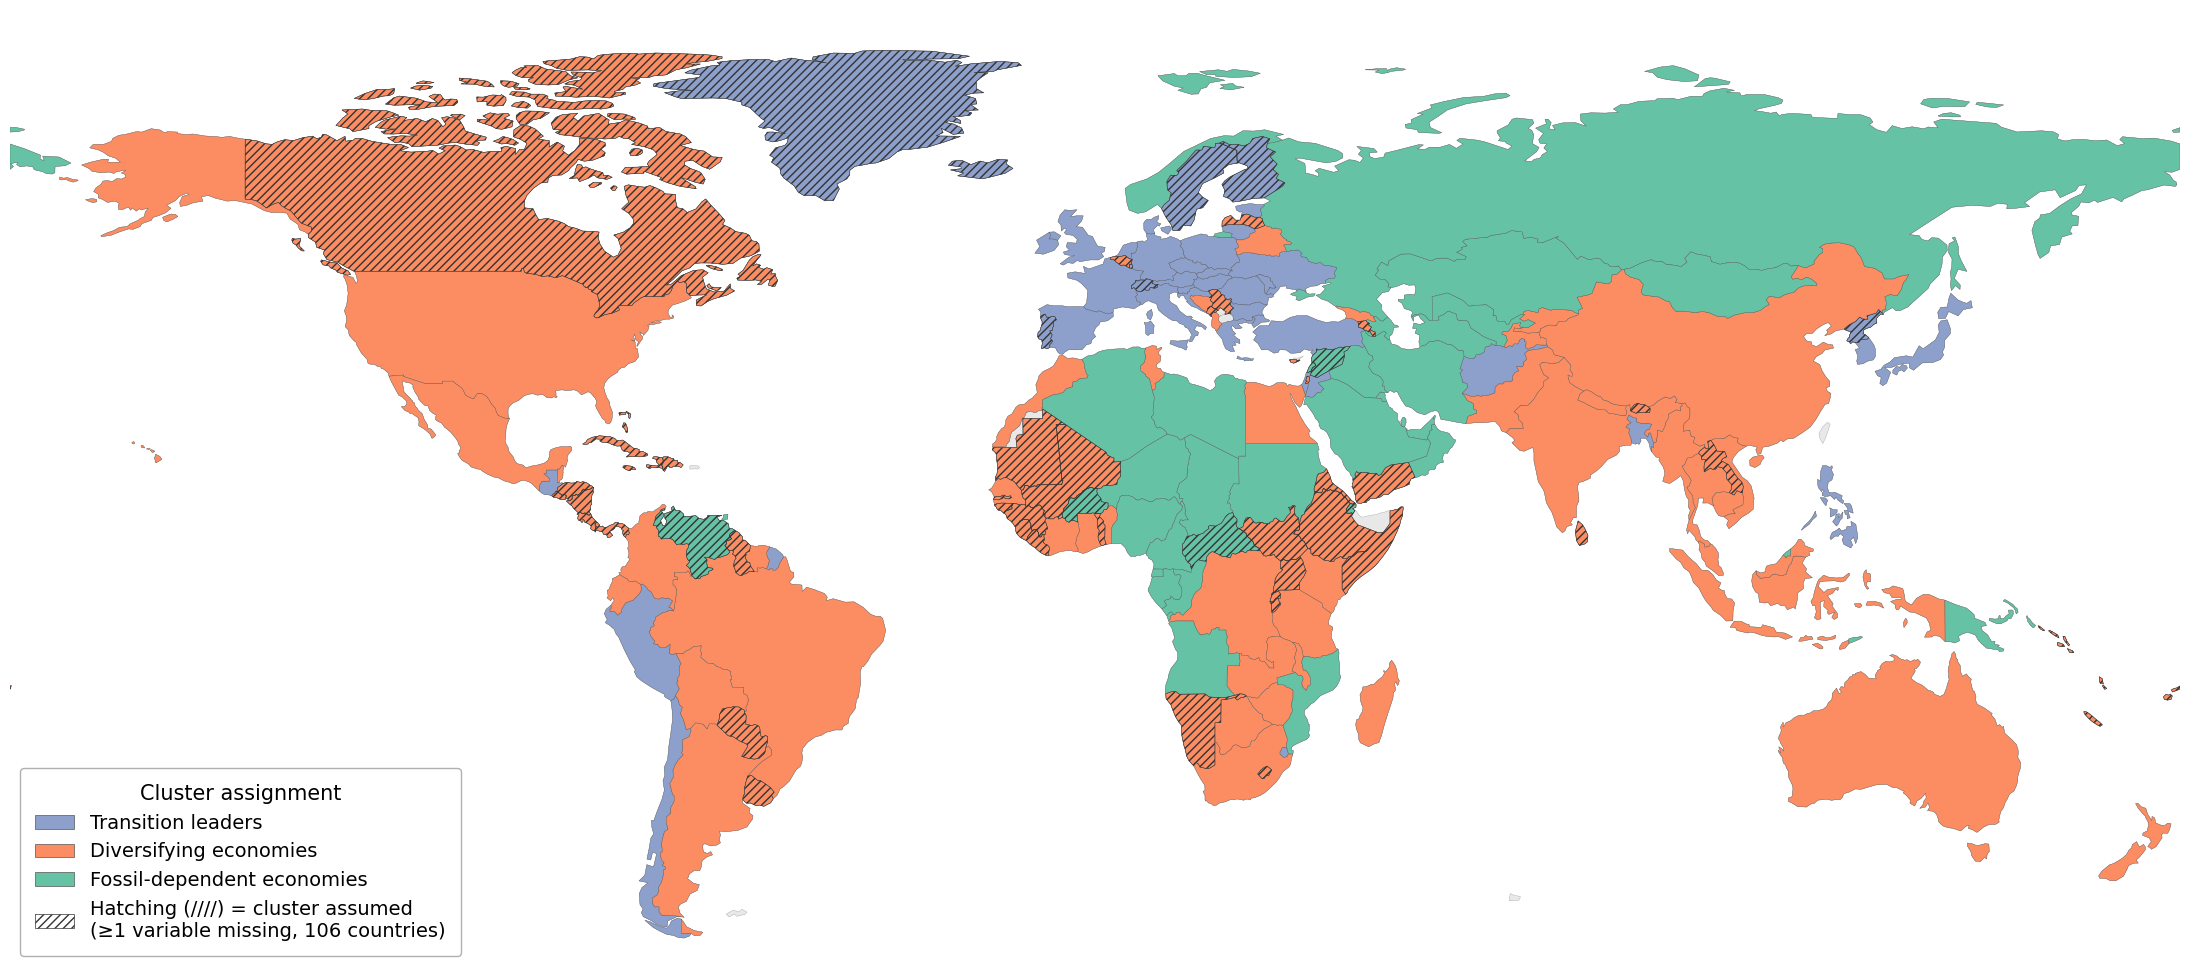

In [4]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import os

# ── Load WP6 protocol classification ──────────────────────────────────────────
PATH_PROTOCOL = r"C:\Users\Dibella\Desktop\CMCC\prisma_diagnostics\PRISMA_WP6_Scenario_Protocol.xlsx"

df_wp6 = pd.read_excel(PATH_PROTOCOL, sheet_name="WP6_classification")
df_wp6 = df_wp6.rename(columns={
    "iso3_code":              "Code",
    "country_name":           "Country",
    "Diversifying economies": "Cluster",
})
df_wp6["Code"] = df_wp6["Code"].astype(str).str.strip().str.upper()
df_wp6 = df_wp6[df_wp6["Code"].str.len() == 3].copy()
df_wp6 = df_wp6.dropna(subset=["Cluster"])
df_wp6 = df_wp6.drop_duplicates(subset=["Code"], keep="first").copy()

for c in ["FF_GDP", "RES_growth", "GHG_intensity"]:
    df_wp6[c] = pd.to_numeric(df_wp6[c], errors="coerce")

df_wp6["has_data"] = df_wp6[["FF_GDP", "RES_growth", "GHG_intensity"]].notna().all(axis=1)

feature_display = {
    "FF_GDP":        "Fossil wealth",
    "RES_growth":    "Renewables growth",
    "GHG_intensity": "GHG intensity",
}

def missing_label(row):
    missing = [label for col, label in feature_display.items() if pd.isna(row.get(col))]
    return ", ".join(missing) if missing else "complete"

df_wp6["Missing_vars"] = df_wp6.apply(missing_label, axis=1)

n_assumed  = (~df_wp6["has_data"]).sum()
assumed_df = df_wp6[~df_wp6["has_data"]]

# ── Load world shapefile ───────────────────────────────────────────────────────
_NE_PATH = (
    r"C:\Users\Dibella\miniconda3\envs\pypsa-eur"
    r"\Lib\site-packages\pyogrio\tests\fixtures\naturalearth_lowres"
    r"\naturalearth_lowres.shp"
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    world = gpd.read_file(_NE_PATH)

# Fix known naturalearth_lowres iso_a3 = "-99" bug
iso_name_fixes = {"Norway": "NOR", "France": "FRA"}
mask_bad = world["iso_a3"] == "-99"
world.loc[mask_bad, "iso_a3"] = world.loc[mask_bad, "name"].map(iso_name_fixes)

world = world.rename(columns={"iso_a3": "Code"})
world = world[world["Code"] != "ATA"]  # remove Antarctica

world = world.merge(
    df_wp6[["Code", "Cluster", "has_data", "Missing_vars"]],
    on="Code", how="left"
)

# ── Print: countries in shapefile with no WP6 assignment ──────────────────────
no_assignment = world[world["Cluster"].isna()][["Code", "name"]].copy()
no_assignment = no_assignment[
    no_assignment["Code"].fillna("").str.match(r"^[A-Z]{3}$")
]
no_assignment = no_assignment.sort_values("name").reset_index(drop=True)

print(f"Countries in shapefile with no WP6 protocol assignment: {len(no_assignment)}")
print()
for _, row in no_assignment.iterrows():
    print(f"  {row['Code']}  {row['name']}")

# ── Plot ───────────────────────────────────────────────────────────────────────
cluster_colors = {
    "Transition leaders":         "#8da0cb",
    "Diversifying economies":     "#fc8d62",
    "Fossil-dependent economies": "#66c2a5",
}

fig, ax = plt.subplots(figsize=(22, 11))
ax.set_facecolor("#dce8f0")

# 1. Neutral base for ALL countries (no legend entry)
world.plot(ax=ax, color="#e8e8e8", edgecolor="#888", linewidth=0.2, zorder=1)

# 2. Solid fill for WP6-assigned countries
for cluster, color in cluster_colors.items():
    sub = world[world["Cluster"] == cluster]
    if not sub.empty:
        sub.plot(ax=ax, color=color, edgecolor="#555", linewidth=0.25, zorder=2)

# 3. Hatch overlay for countries whose cluster was assumed (≥1 variable missing)
for cluster in cluster_colors:
    assumed = world[(world["Cluster"] == cluster) & (world["has_data"] == False)]
    if not assumed.empty:
        assumed.plot(ax=ax, color="none", edgecolor="#333",
                     linewidth=0.35, hatch="////", zorder=3)

ax.set_xlim(-180, 180)
ax.set_ylim(-60, 90)
ax.set_axis_off()

# ── Legend ─────────────────────────────────────────────────────────────────────
legend_elements = [
    mpatches.Patch(facecolor=color, edgecolor="#555", linewidth=0.5, label=cluster)
    for cluster, color in cluster_colors.items()
]
legend_elements.append(
    mpatches.Patch(
        facecolor="white", edgecolor="#333", hatch="////", linewidth=0.5,
        label=f"Hatching (////) = cluster assumed\n(≥1 variable missing, {n_assumed} countries)"
    )
)

ax.legend(
    handles=legend_elements,
    loc="lower left",
    fontsize=14,
    title="Cluster assignment",
    title_fontsize=15,
    framealpha=0.92,
    edgecolor="#aaa",
    borderpad=0.8,
)

ax.set_title("", fontsize=18, fontweight="bold", pad=10)

plt.tight_layout()

# ── Save to project graphs folder (../graphs/ relative to scripts/) ────────────
_out_dir = os.path.normpath(os.path.join(os.getcwd(), "..", "graphs"))
os.makedirs(_out_dir, exist_ok=True)


WP6-assigned countries total:              215
  GMM-assigned (all 3 features present):  109
  Expert-assigned (≥1 feature missing):   106

Missing-variable breakdown (hatched countries):
  Fossil wealth (70):  ABW, ARM, ATG, BDI, BEL, BFA, BHS, BTN, CAF, CAN, CHE, COM, CPV, CRI, CYP, DJI, DMA, DOM, ETH, FIN, FJI, FRO, GIN, GMB, GNB, GRD, GRL, GUY, HKG, HND, HTI, ISL, JAM, KIR, KNA, LAO, LBN, LBR, LCA, LKA, LSO, LUX, LVA, MDV, MLI, MLT, MRT, MUS, NAM, NIC, PAN, PLW, PRT, PRY, RWA, SGP, SLB, SLE, SLV, SOM, STP, SWE, SYC, SYR, TGO, TON, UGA, URY, VUT, WSM
  Fossil wealth, GHG intensity (20):  AND, ASM, CUB, CUW, ERI, FSM, GUM, MAF, MHL, NCL, NRU, PRK, PSE, PYF, SSD, TUV, VEN, VGB, VIR, YEM
  Fossil wealth, RES growth (5):  BMU, CYM, MAC, TCA, VCT
  Fossil wealth, RES growth, GHG intensity (8):  CHI, GIB, IMN, LIE, MCO, MNP, SMR, SXM
  GHG intensity (3):  MNE, SRB, XKX

══════════════════════════════════════════════════════════════════════
VALIDATION  (98 expert-assigned countries with ≥1

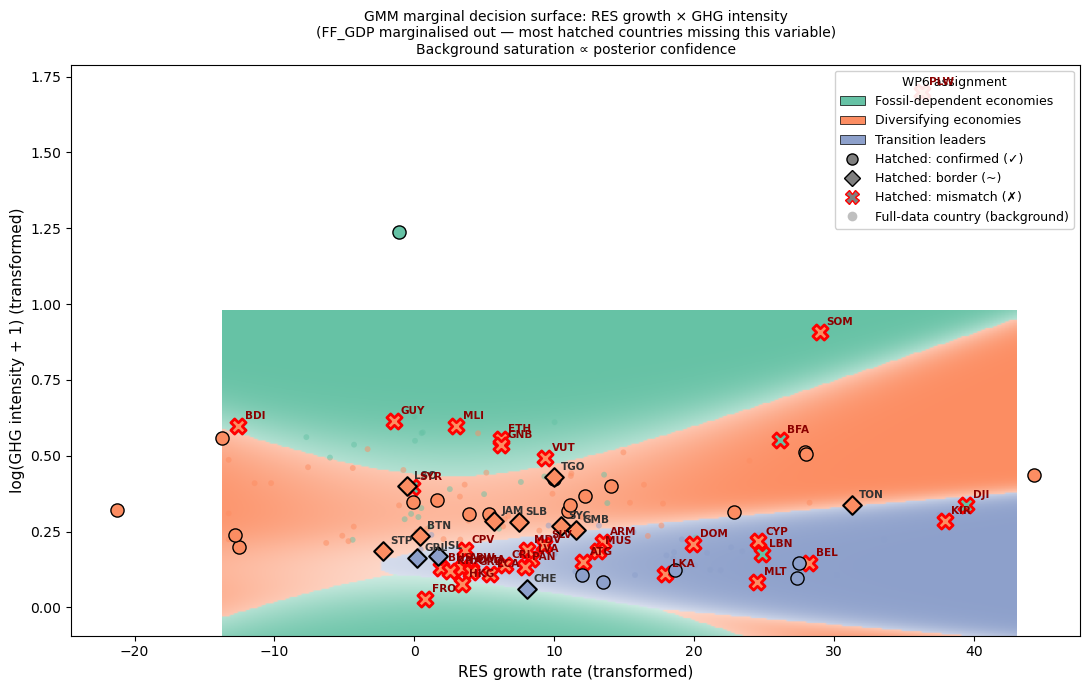

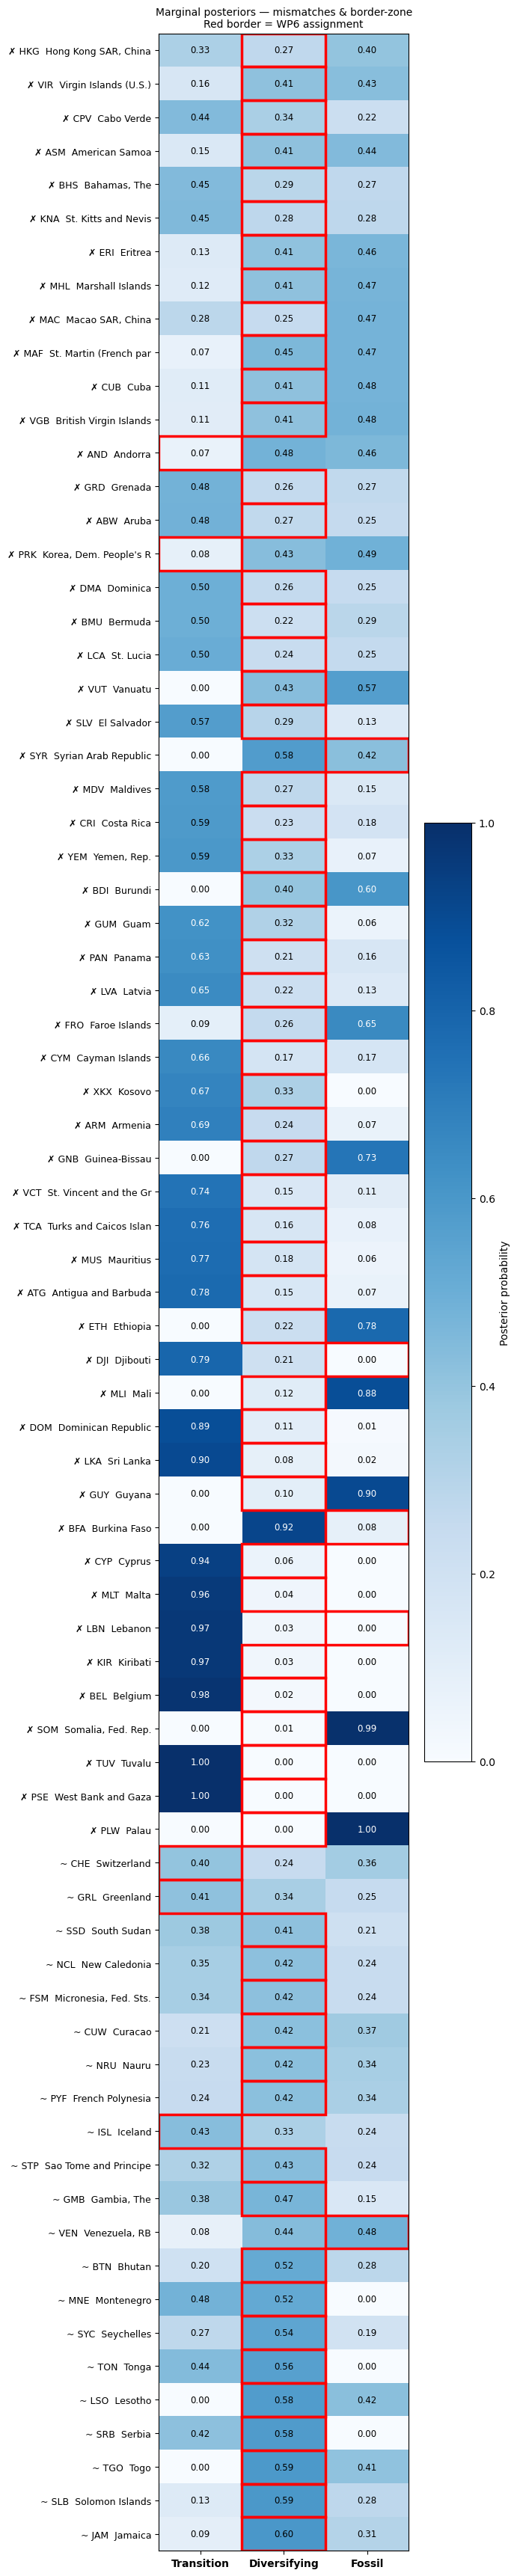

In [5]:

# ═══════════════════════════════════════════════════════════════════════════════
# Validation: rigorous posterior-probability check for expert-assigned countries
#
# Hatched countries on the map have ≥1 missing indicator and were assigned by
# expert judgement.  Here we test those assignments using the *marginal*
# posterior of the fitted GMM restricted to whatever features ARE available.
#
# With diagonal covariance, features are conditionally independent given the
# cluster, so the marginal likelihood for an observed subset is:
#   log p(x_obs | k) = Σ_{j ∈ obs} log N(x_j ; μ_kj, σ²_kj)
#   posterior  p(k | x_obs) ∝ π_k · p(x_obs | k)
#
# Three output tiers:
#   ✗  Mismatch  — GMM best cluster ≠ WP6 expert assignment
#   ~  Border    — max posterior < 0.60 (assignment ambiguous)
#   ✓  Confirmed — GMM agrees with high confidence
#
# Requires the GMM cell (cell 3) to have already run.
# Variables used from that cell: gmm, scaler, label_map, features_t, df_fit
# ═══════════════════════════════════════════════════════════════════════════════

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

# ── Reload WP6 protocol with expert assignments ──────────────────────────────
_out_dir_val = globals().get("_out_dir", os.path.join("..", "graphs"))

df_wp6v = pd.read_excel(PATH_PROTOCOL, sheet_name="WP6_classification")
df_wp6v = df_wp6v.rename(columns={
    "iso3_code":              "Code",
    "country_name":           "Country",
    "Diversifying economies": "Cluster",
})
df_wp6v["Code"] = df_wp6v["Code"].astype(str).str.strip().str.upper()
df_wp6v = df_wp6v[df_wp6v["Code"].str.len() == 3].copy()
df_wp6v = df_wp6v.dropna(subset=["Cluster"])
df_wp6v = df_wp6v.drop_duplicates(subset=["Code"], keep="first").copy()

for c in ["FF_GDP", "RES_growth", "GHG_intensity"]:
    df_wp6v[c] = pd.to_numeric(df_wp6v[c], errors="coerce")

_feat_disp = {
    "FF_GDP":        "Fossil wealth",
    "RES_growth":    "RES growth",
    "GHG_intensity": "GHG intensity",
}
df_wp6v["missing"]   = df_wp6v.apply(
    lambda r: ", ".join(lbl for col, lbl in _feat_disp.items() if pd.isna(r[col])) or "—", axis=1
)
df_wp6v["n_missing"] = df_wp6v[["FF_GDP", "RES_growth", "GHG_intensity"]].isna().sum(axis=1)
df_wp6v["has_all"]   = (df_wp6v["n_missing"] == 0)

df_partial = df_wp6v[df_wp6v["has_all"] == False].copy()

print(f"WP6-assigned countries total:              {len(df_wp6v)}")
print(f"  GMM-assigned (all 3 features present):  {int(df_wp6v['has_all'].sum())}")
print(f"  Expert-assigned (≥1 feature missing):   {len(df_partial)}")
print(f"\nMissing-variable breakdown (hatched countries):")
for miss, grp in df_partial.groupby("missing"):
    print(f"  {miss} ({len(grp)}):  {', '.join(sorted(grp['Code']))}")


# ── Marginal posterior from the fitted GMM ───────────────────────────────────
def gmm_marginal_posterior(row, gmm, scaler, features_t):
    obs = {}
    if pd.notna(row.get("FF_GDP")) and row["FF_GDP"] > 0:
        obs["FF_GDP_t"]        = np.log1p(row["FF_GDP"])
    if pd.notna(row.get("RES_growth")):
        obs["RES_growth_t"]    = float(row["RES_growth"])
    if pd.notna(row.get("GHG_intensity")) and row["GHG_intensity"] > 0:
        obs["GHG_intensity_t"] = np.log1p(row["GHG_intensity"])

    avail = [(f, features_t.index(f)) for f in obs if f in features_t]
    if not avail:
        return None, 0

    feat_names, feat_idx = zip(*avail)
    feat_idx = list(feat_idx)
    x_raw = np.array([obs[f] for f in feat_names], dtype=float)
    x_sc  = (x_raw - scaler.mean_[feat_idx]) / scaler.scale_[feat_idx]

    log_p = np.zeros(gmm.n_components)
    for k in range(gmm.n_components):
        mu_k  = gmm.means_[k][feat_idx]
        var_k = gmm.covariances_[k][feat_idx]
        diff  = x_sc - mu_k
        log_p[k] = (
            np.log(gmm.weights_[k])
            - 0.5 * np.sum(diff**2 / var_k)
            - 0.5 * np.sum(np.log(2.0 * np.pi * var_k))
        )
    log_p -= log_p.max()
    probs  = np.exp(log_p)
    return probs / probs.sum(), len(avail)


# ── Run for every expert-assigned country ───────────────────────────────────
cluster_order = [label_map[k] for k in range(gmm.n_components)]
SHORT = {
    "Fossil-dependent economies": "Fossil",
    "Diversifying economies":     "Diversifying",
    "Transition leaders":         "Transition",
}

records = []
for _, row in df_partial.iterrows():
    probs, n_feat = gmm_marginal_posterior(row, gmm, scaler, features_t)
    base = dict(Code=str(row["Code"]), Country=str(row["Country"]),
                WP6=str(row["Cluster"]), n_feat=int(n_feat),
                missing=str(row["missing"]))
    if probs is None:
        records.append({**base, "Model": "—", "max_prob": float("nan"),
                        "agrees": 0,   # 0 = untestable (n_feat==0)
                        **{c: float("nan") for c in cluster_order}})
    else:
        model_cl = cluster_order[int(np.argmax(probs))]
        records.append({**base, "Model": model_cl,
                        "max_prob": float(probs.max()),
                        "agrees": int(str(row["Cluster"]) == str(model_cl)),  # 1=yes, 0=no
                        **{c: float(v) for c, v in zip(cluster_order, probs)}})

df_val = pd.DataFrame(records)
# 'agrees' is now int: 1 = GMM agrees, 0 = disagrees or untestable
# Use explicit integer comparisons throughout — avoids any dtype / ~ issues

def tier(r):
    if r["n_feat"] == 0:      return "untestable"
    if r["agrees"] != 1:      return "mismatch"
    if r["max_prob"] < 0.60:  return "border"
    return "confirmed"
df_val["tier"] = df_val.apply(tier, axis=1)

df_testable = df_val[df_val["n_feat"] > 0].copy()

n_agree  = int((df_testable["agrees"] == 1).sum())
n_mm     = int((df_testable["agrees"] == 0).sum())
n_border = int((df_testable["max_prob"] < 0.60).sum())
n_unt    = int((df_val["n_feat"] == 0).sum())

print(f"\n{'═'*70}")
print(f"VALIDATION  ({len(df_testable)} expert-assigned countries with ≥1 available feature)")
print(f"{'═'*70}")
print(f"  ✓ Confirmed (GMM agrees, p ≥ 0.60):    {n_agree - n_border:3d}")
print(f"  ~ Border    (GMM agrees, p <  0.60):    {n_border:3d}  ← assignment uncertain")
print(f"  ✗ Mismatch  (GMM picks different):      {n_mm:3d}  ← review these")
print(f"  — Untestable (no features at all):       {n_unt:3d}  (purely qualitative)")

print(f"\n{'─'*70}")
print("MISMATCHES — WP6 expert assignment differs from GMM marginal prediction:")
print(f"{'─'*70}")
mm = df_testable[df_testable["agrees"] == 0].sort_values("max_prob")
if mm.empty:
    print("  None — all testable expert assignments agree with the GMM.")
else:
    for _, r in mm.iterrows():
        prob_str = "  ".join(
            f"{SHORT.get(c,c)[:6]}:{r[c]:.2f}"
            for c in cluster_order if c in r and pd.notna(r[c])
        )
        print(f"  {r['Code']:<4}  {r['Country'][:30]:<30}  "
              f"WP6={SHORT.get(r['WP6'],'?'):<14}  GMM={SHORT.get(r['Model'],'?'):<14}  "
              f"[{prob_str}]  n_feat={r['n_feat']}  miss=[{r['missing']}]")

print(f"\n{'─'*70}")
print("BORDER ZONE — max posterior < 0.60 (near a decision boundary):")
print(f"{'─'*70}")
bz = df_testable[df_testable["max_prob"] < 0.60].sort_values("max_prob")
if bz.empty:
    print("  None.")
else:
    for _, r in bz.iterrows():
        flag = "✗" if r["agrees"] != 1 else "~"
        prob_str = "  ".join(
            f"{SHORT.get(c,c)[:6]}:{r[c]:.2f}"
            for c in cluster_order if c in r and pd.notna(r[c])
        )
        print(f"  {flag} {r['Code']:<4}  {r['Country'][:30]:<30}  "
              f"WP6={SHORT.get(r['WP6'],'?'):<14}  "
              f"p_max={r['max_prob']:.2f}  [{prob_str}]  miss=[{r['missing']}]")

print(f"\n{'─'*70}")
print("UNTESTABLE — no indicator available, purely qualitative assignment:")
print(f"{'─'*70}")
unt = df_val[df_val["n_feat"] == 0]
if unt.empty:
    print("  None.")
else:
    for _, r in unt.iterrows():
        print(f"  {r['Code']:<4}  {r['Country'][:30]:<30}  "
              f"WP6={SHORT.get(r['WP6'],'?'):<14}  miss=[{r['missing']}]")


# ── Scatter: RES growth × GHG intensity — GMM marginal decision surface ─────
CLUSTER_COLORS = {
    "Fossil-dependent economies": "#66c2a5",
    "Diversifying economies":     "#fc8d62",
    "Transition leaders":         "#8da0cb",
}

res_min = df_fit["RES_growth_t"].min() - 0.5
res_max = df_fit["RES_growth_t"].max() + 0.5
ghg_min = df_fit["GHG_intensity_t"].min() - 0.2
ghg_max = df_fit["GHG_intensity_t"].max() + 0.2
ng = 200
GG_res, GG_ghg = np.meshgrid(np.linspace(res_min, res_max, ng),
                               np.linspace(ghg_min, ghg_max, ng))

feat_2d_idx = [features_t.index("RES_growth_t"), features_t.index("GHG_intensity_t")]
grid_pts = np.column_stack([GG_res.ravel(), GG_ghg.ravel()])
grid_sc  = (grid_pts - scaler.mean_[feat_2d_idx]) / scaler.scale_[feat_2d_idx]

log_p_grid = np.zeros((grid_pts.shape[0], gmm.n_components))
for k in range(gmm.n_components):
    mu_k  = gmm.means_[k][feat_2d_idx]
    var_k = gmm.covariances_[k][feat_2d_idx]
    diff  = grid_sc - mu_k
    log_p_grid[:, k] = (
        np.log(gmm.weights_[k])
        - 0.5 * np.sum(diff**2 / var_k, axis=1)
        - 0.5 * np.sum(np.log(2 * np.pi * var_k))
    )
log_p_grid -= log_p_grid.max(axis=1, keepdims=True)
p_grid = np.exp(log_p_grid); p_grid /= p_grid.sum(axis=1, keepdims=True)
best_k_grid = np.argmax(p_grid, axis=1).reshape(ng, ng)
max_p_grid  = p_grid.max(axis=1).reshape(ng, ng)

cmap_grid = np.zeros((ng, ng, 3))
for k, cl in enumerate(cluster_order):
    cmap_grid[best_k_grid == k] = mcolors.to_rgb(CLUSTER_COLORS.get(cl, "#cccccc"))
alpha  = np.clip(max_p_grid, 0, 1)[..., np.newaxis]
bg_img = alpha * cmap_grid + (1 - alpha)

fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(bg_img, extent=[res_min, res_max, ghg_min, ghg_max],
          origin="lower", aspect="auto", zorder=0)

df_fit_plot = df_fit.copy()
df_fit_plot["Cluster"] = df_fit_plot["_cluster"].map(label_map)
for cl, color in CLUSTER_COLORS.items():
    sub = df_fit_plot[df_fit_plot["Cluster"] == cl]
    ax.scatter(sub["RES_growth_t"], sub["GHG_intensity_t"],
               c=color, s=18, alpha=0.5, edgecolors="none", zorder=2)

df_h2d = df_partial.dropna(subset=["RES_growth", "GHG_intensity"]).copy()
df_h2d["RES_t"] = df_h2d["RES_growth"]
df_h2d["GHG_t"] = np.log1p(df_h2d["GHG_intensity"].clip(lower=0))
df_h2d = df_h2d.merge(df_val[["Code", "tier", "WP6"]], on="Code", how="left")

marker_map = {"confirmed": ("o", "black", 1.0, 90),
              "border":    ("D", "black", 1.5, 90),
              "mismatch":  ("X", "red",   2.0, 120)}
for cl, color in CLUSTER_COLORS.items():
    for t, (mk, ec, lw, sz) in marker_map.items():
        sub = df_h2d[(df_h2d["WP6"] == cl) & (df_h2d["tier"] == t)]
        if not sub.empty:
            ax.scatter(sub["RES_t"], sub["GHG_t"], c=color, s=sz,
                       edgecolors=ec, linewidths=lw, marker=mk, zorder=4)

for _, r in df_h2d[df_h2d["tier"].isin(["mismatch", "border"])].iterrows():
    ax.annotate(r["Code"], xy=(r["RES_t"], r["GHG_t"]),
                xytext=(5, 5), textcoords="offset points", fontsize=7.5,
                fontweight="bold",
                color="darkred" if r["tier"] == "mismatch" else "#333", zorder=7)

legend_els = [mpatches.Patch(facecolor=c, edgecolor="black", lw=0.5, label=cl)
              for cl, c in CLUSTER_COLORS.items()]
legend_els += [
    plt.Line2D([0],[0], marker="o", color="w", markerfacecolor="grey",
               markeredgecolor="black", ms=8, label="Hatched: confirmed (✓)"),
    plt.Line2D([0],[0], marker="D", color="w", markerfacecolor="grey",
               markeredgecolor="black", ms=8, label="Hatched: border (~)"),
    plt.Line2D([0],[0], marker="X", color="w", markerfacecolor="grey",
               markeredgecolor="red",   ms=10, label="Hatched: mismatch (✗)"),
    plt.Line2D([0],[0], marker="o", color="w", markerfacecolor="grey",
               markeredgecolor="none",  ms=7, alpha=0.5,
               label="Full-data country (background)"),
]
ax.legend(handles=legend_els, fontsize=9, loc="upper right",
          framealpha=0.9, title="WP6 assignment", title_fontsize=9)
ax.set_xlabel("RES growth rate (transformed)", fontsize=11)
ax.set_ylabel("log(GHG intensity + 1) (transformed)", fontsize=11)
ax.set_title(
    "GMM marginal decision surface: RES growth × GHG intensity\n"
    "(FF_GDP marginalised out — most hatched countries missing this variable)\n"
    "Background saturation ∝ posterior confidence",
    fontsize=10, pad=8)
plt.tight_layout()


# ── Posterior heatmap: mismatches + border zone only ─────────────────────────
df_flag = df_testable[df_testable["tier"].isin(["mismatch", "border"])].copy()
df_flag = df_flag.sort_values(["tier", "max_prob"],
                               ascending=[False, True]).reset_index(drop=True)

if len(df_flag) > 0:
    prob_mat = df_flag[cluster_order].fillna(0).values
    ylabels  = [f"{'✗' if r.tier=='mismatch' else '~'} {r.Code}  {r.Country[:22]}"
                for _, r in df_flag.iterrows()]
    xlabels  = [SHORT.get(c, c) for c in cluster_order]

    fig2, ax2 = plt.subplots(figsize=(7, max(2.5, len(df_flag) * 0.45 + 0.8)))
    im = ax2.imshow(prob_mat, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax2.set_xticks(range(len(cluster_order)))
    ax2.set_xticklabels(xlabels, fontsize=10, fontweight="bold")
    ax2.set_yticks(range(len(df_flag)))
    ax2.set_yticklabels(ylabels, fontsize=9)
    ax2.set_title("Marginal posteriors — mismatches & border-zone\nRed border = WP6 assignment",
                  fontsize=10, pad=6)

    for i in range(len(df_flag)):
        for j, cl in enumerate(cluster_order):
            v = prob_mat[i, j]
            ax2.text(j, i, f"{v:.2f}", ha="center", va="center",
                     fontsize=8.5, color="white" if v > 0.6 else "black")
        wp6_j = (cluster_order.index(df_flag.loc[i, "WP6"])
                 if df_flag.loc[i, "WP6"] in cluster_order else None)
        if wp6_j is not None:
            ax2.add_patch(plt.Rectangle((wp6_j - 0.5, i - 0.5), 1, 1,
                                        lw=2.5, edgecolor="red", facecolor="none"))

    plt.colorbar(im, ax=ax2, shrink=0.6, label="Posterior probability")
    plt.tight_layout()
else:
    print("No mismatches or border-zone countries — nothing to plot in heatmap.")


Tier counts: GMM=109  Confirmed=44  Eyeballed=62

GHG SHARE BY EVIDENCE TIER  (GHG_intensity x GDP_PPP)
Tier                                        n    Share
--------------------------------------------------------------
GMM-assigned  (solid)                     109    95.8%
Confirmed/border  (////)                   44     2.8%
Expert-eyeballed  (xxxx)                   62     1.4%
--------------------------------------------------------------
  of which mismatch                        54    1.45%
  of which untestable                       8    0.00%

GDP (PPP) SHARE BY EVIDENCE TIER
Tier                                        n   GDP PPP (bn$)    Share
--------------------------------------------------------------
GMM-assigned  (solid)                     109          135437    93.8%
Confirmed/border  (////)                   44            5843     4.0%
Expert-eyeballed  (xxxx)                   62            3074     2.1%
-----------------------------------------------------------

C:\Users\Dibella\AppData\Local\Temp\ipykernel_25668\474362277.py:26: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



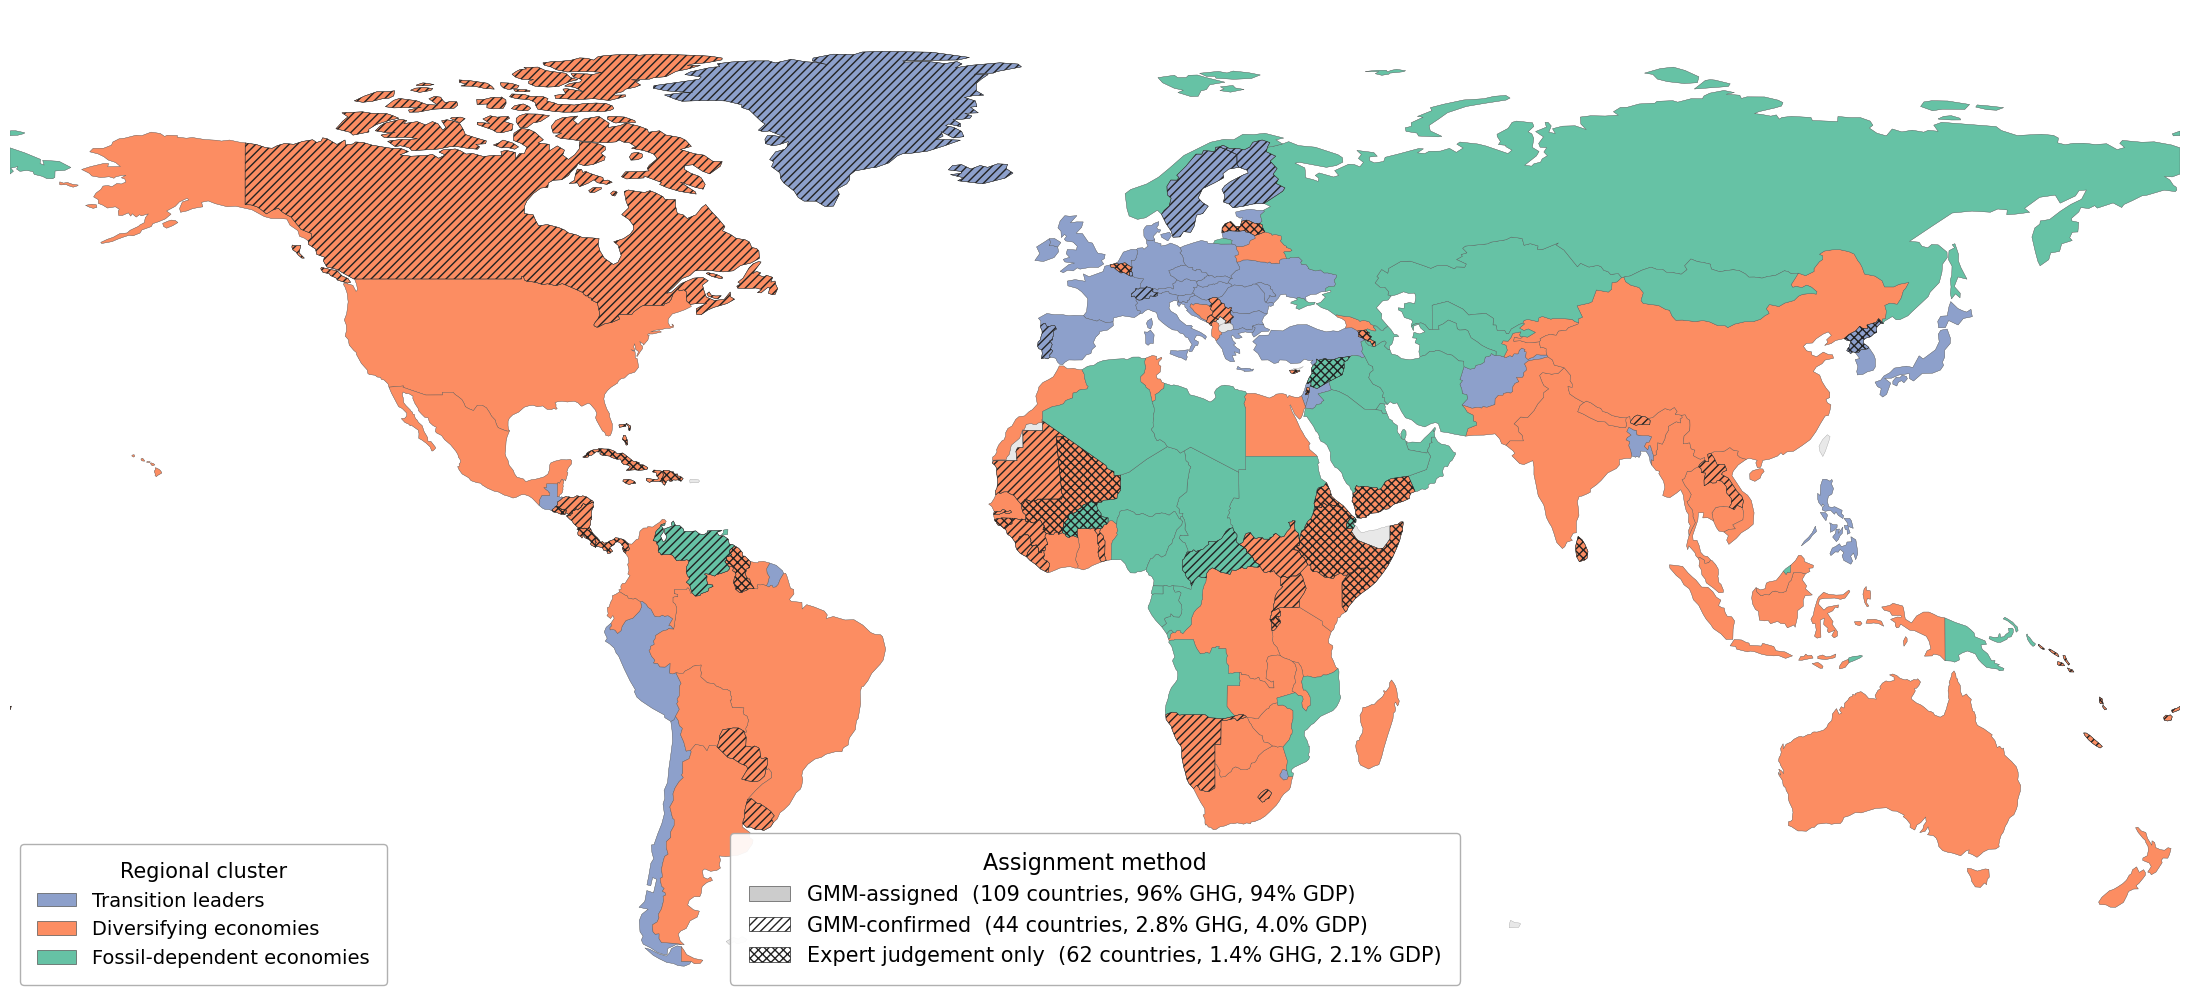

Map saved: C:\Users\Dibella\Desktop\CMCC\prisma_wp6_analysis\graphs\fig_sm1.png


In [6]:
# === 4-layer map + GHG and GDP share per evidence tier ===
# Requires: df_wp6v (has_all), df_val (tier), PATH, _out_dir from previous cells
import os, warnings
import numpy as np, pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# 1. Assign evidence tier
_tier_lookup = df_val.set_index("Code")["tier"].to_dict()

def _assign_map_tier(row):
    if row["has_all"]:
        return "gmm"
    t = _tier_lookup.get(row["Code"])
    if t in ("confirmed", "border"):
        return "confirmed"
    return "eyeballed"

df_wp6v["map_tier"] = df_wp6v.apply(_assign_map_tier, axis=1)
_tc = df_wp6v["map_tier"].value_counts()
print(f"Tier counts: GMM={_tc.get('gmm',0)}  Confirmed={_tc.get('confirmed',0)}  Eyeballed={_tc.get('eyeballed',0)}")

# 2. Load GDP_PPP and compute GHG proxy
_df_gdp = pd.read_excel(PATH, sheet_name=0, skiprows=8)
_df_gdp = _df_gdp.replace({"..": np.nan, "#VALUE!": np.nan, "#N/A": np.nan, "": np.nan})
_df_gdp = _df_gdp.rename(columns={
    "Country code": "Code",
    "GDP, PPP (constant 2021 international $)": "GDP_PPP",
})
_df_gdp["Code"] = _df_gdp["Code"].astype(str).str.strip().str.upper()
_df_gdp = _df_gdp[_df_gdp["Code"].str.len() == 3].drop_duplicates(subset=["Code"]).copy()
_df_gdp["GDP_PPP"] = pd.to_numeric(_df_gdp["GDP_PPP"], errors="coerce")

_merged = df_wp6v.merge(_df_gdp[["Code", "GDP_PPP"]], on="Code", how="left")
_merged["GHG_intensity_num"] = pd.to_numeric(_merged["GHG_intensity"], errors="coerce")
_merged["GHG_proxy"] = _merged["GHG_intensity_num"] * _merged["GDP_PPP"]

_mm_codes  = set(df_val[df_val["tier"] == "mismatch"]["Code"])
_unt_codes = set(df_val[df_val["tier"] == "untestable"]["Code"])

def _share(mask, col):
    tot = _merged[col].sum()
    s   = float(_merged.loc[mask, col].sum())
    n   = int(mask.sum())
    return s, n, 100.0 * s / tot if tot > 0 else 0.0

# 3. GHG shares
_s_gmm,  _n_gmm,  _p_gmm   = _share(_merged["map_tier"] == "gmm",      "GHG_proxy")
_s_conf, _n_conf, _p_conf   = _share(_merged["map_tier"] == "confirmed", "GHG_proxy")
_s_eye,  _n_eye,  _p_eye    = _share(_merged["map_tier"] == "eyeballed", "GHG_proxy")
_s_mm,   _n_mm_g, _p_mm_g   = _share(_merged["Code"].isin(_mm_codes),   "GHG_proxy")
_s_unt,  _n_unt_g, _p_unt_g = _share(_merged["Code"].isin(_unt_codes),  "GHG_proxy")

print("\n" + "=" * 62)
print("GHG SHARE BY EVIDENCE TIER  (GHG_intensity x GDP_PPP)")
print("=" * 62)
print(f"{'Tier':<40} {'n':>4}  {'Share':>7}")
print("-" * 62)
print(f"{'GMM-assigned  (solid)':<40} {_n_gmm:>4}  {_p_gmm:>6.1f}%")
print(f"{'Confirmed/border  (////)' :<40} {_n_conf:>4}  {_p_conf:>6.1f}%")
print(f"{'Expert-eyeballed  (xxxx)':<40} {_n_eye:>4}  {_p_eye:>6.1f}%")
print("-" * 62)
print(f"{'  of which mismatch':<40} {_n_mm_g:>4}  {_p_mm_g:>6.2f}%")
print(f"{'  of which untestable':<40} {_n_unt_g:>4}  {_p_unt_g:>6.2f}%")

# 4. GDP shares
_g_gmm,  _, _gp_gmm  = _share(_merged["map_tier"] == "gmm",      "GDP_PPP")
_g_conf, _, _gp_conf  = _share(_merged["map_tier"] == "confirmed", "GDP_PPP")
_g_eye,  _, _gp_eye   = _share(_merged["map_tier"] == "eyeballed", "GDP_PPP")
_g_mm,   _, _gp_mm    = _share(_merged["Code"].isin(_mm_codes),   "GDP_PPP")
_g_unt,  _, _gp_unt   = _share(_merged["Code"].isin(_unt_codes),  "GDP_PPP")
_total_gdp = _merged["GDP_PPP"].sum()

print("\n" + "=" * 62)
print("GDP (PPP) SHARE BY EVIDENCE TIER")
print("=" * 62)
print(f"{'Tier':<40} {'n':>4}  {'GDP PPP (bn$)':>14}  {'Share':>7}")
print("-" * 62)
print(f"{'GMM-assigned  (solid)':<40} {_n_gmm:>4}  {_g_gmm/1e9:>14.0f}  {_gp_gmm:>6.1f}%")
print(f"{'Confirmed/border  (////)' :<40} {_n_conf:>4}  {_g_conf/1e9:>14.0f}  {_gp_conf:>6.1f}%")
print(f"{'Expert-eyeballed  (xxxx)':<40} {_n_eye:>4}  {_g_eye/1e9:>14.0f}  {_gp_eye:>6.1f}%")
print("-" * 62)
print(f"{'TOTAL':<40} {_n_gmm+_n_conf+_n_eye:>4}  {_total_gdp/1e9:>14.0f}  {'100.0%':>7}")
print(f"{'  of which mismatch':<40} {'':>4}  {_g_mm/1e9:>14.0f}  {_gp_mm:>6.2f}%")
print(f"{'  of which untestable':<40} {'':>4}  {_g_unt/1e9:>14.0f}  {_gp_unt:>6.2f}%")

# 5. Load shapefile
_NE_PATH = (r"C:\Users\Dibella\miniconda3\envs\pypsa-eur"
            r"\Lib\site-packages\pyogrio\tests\fixtures\naturalearth_lowres"
            r"\naturalearth_lowres.shp")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    _world = gpd.read_file(_NE_PATH)

_bad = _world["iso_a3"] == "-99"
_world.loc[_bad, "iso_a3"] = _world.loc[_bad, "name"].map({"Norway": "NOR", "France": "FRA"})
_world = _world.rename(columns={"iso_a3": "Code"})
_world = _world[_world["Code"] != "ATA"]
_world = _world.merge(_merged[["Code", "Cluster", "map_tier"]], on="Code", how="left")

# 6. Draw map
_CC = {
    "Transition leaders":         "#8da0cb",
    "Diversifying economies":     "#fc8d62",
    "Fossil-dependent economies": "#66c2a5",
}
fig, ax = plt.subplots(figsize=(22, 11))
ax.set_facecolor("#dce8f0")
_world.plot(ax=ax, color="#e8e8e8", edgecolor="#888", linewidth=0.2, zorder=1)

for _cl, _col in _CC.items():
    _sub = _world[(_world["Cluster"] == _cl) & (_world["map_tier"] == "gmm")]
    if not _sub.empty:
        _sub.plot(ax=ax, color=_col, edgecolor="#555", linewidth=0.25, zorder=2)
    _sub = _world[(_world["Cluster"] == _cl) & (_world["map_tier"] == "confirmed")]
    if not _sub.empty:
        _sub.plot(ax=ax, color=_col,   edgecolor="#555", linewidth=0.25, zorder=2)
        _sub.plot(ax=ax, color="none", edgecolor="#222", linewidth=0.3,  hatch="////", zorder=3)
    _sub = _world[(_world["Cluster"] == _cl) & (_world["map_tier"] == "eyeballed")]
    if not _sub.empty:
        _sub.plot(ax=ax, color=_col,   edgecolor="#555", linewidth=0.25, zorder=2)
        _sub.plot(ax=ax, color="none", edgecolor="#222", linewidth=0.3,  hatch="xxxx", zorder=3)

ax.set_xlim(-180, 180); ax.set_ylim(-60, 90); ax.set_axis_off()

# 7. Two legends
leg1 = ax.legend(
    handles=[mpatches.Patch(facecolor=c, edgecolor="#555", lw=0.5, label=cl) for cl, c in _CC.items()],
    loc="lower left", fontsize=14, title="Regional cluster", title_fontsize=15,
    framealpha=0.93, edgecolor="#aaa", borderpad=0.9,
)
ax.add_artist(leg1)

ax.legend(
    handles=[
        mpatches.Patch(facecolor="#cccccc", edgecolor="#555", lw=0.5,
                       label=f"GMM-assigned  ({_n_gmm} countries, {_p_gmm:.0f}% GHG, {_gp_gmm:.0f}% GDP)"),
        mpatches.Patch(facecolor="white", edgecolor="#222", hatch="////", lw=0.5,
                       label=f"GMM-confirmed  ({_n_conf} countries, {_p_conf:.1f}% GHG, {_gp_conf:.1f}% GDP)"),
        mpatches.Patch(facecolor="white", edgecolor="#222", hatch="xxxx", lw=0.5,
                       label=f"Expert judgement only  ({_n_eye} countries, {_p_eye:.1f}% GHG, {_gp_eye:.1f}% GDP)"),
    ],
    loc="lower center", fontsize=15, title="Assignment method", title_fontsize=16,
    framealpha=0.93, edgecolor="#aaa", borderpad=0.9,
)

plt.tight_layout()

_out_dir_tier = globals().get("_out_dir", os.path.join("..", "graphs"))
_map_tier_path = os.path.join(_out_dir_tier, "fig_sm1.png")
fig.savefig(_map_tier_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Map saved: {_map_tier_path}")
